# FieldRota-AI: a reinforcement-learning crop rotation planner for a hotter, drier future
**Track: Climate** · Veritas AI International High School Hackathon 2026

**Problem.** In groundwater hotspots such as the Konya Plain (Türkiye), Kansas (Ogallala), Punjab, California's Central Valley and La Mancha, farmers pump aquifers faster than they refill. The crop rotation (which crop follows which) decides how much well water a field needs, how healthy its soil stays, and how well it copes with more hot days. Farmers need a plan for *this* field, starting from what is in it today, that still works as the climate warms.

**What we built.** FieldRota is our web app. Its first version (v1) scored every 3-year rotation once with the *average* climate and suggested the best one. **FieldRota-AI** replaces that with a **learned policy**: a tabular **Q-learning** agent that, every year, looks at the last two crops on the field (and the decade, or last year's rainfall) and picks the next crop. It learns by trial and error in a field simulator driven by **real NASA POWER weather (1986–2008)** and **three NASA NEX-GDDP-CMIP6 climate models (2026–2060)**, using FieldRota's own calibrated crop data, rules and scoring.

**How we test it (honestly).**
1. *Unseen real weather:* trained on 1986–2008, best of 3 training runs chosen on 2009–2014 (validation), tested on **2015–2025**.
2. *Unseen climate models:* trained on 3 CMIP6 models, best run chosen on a 4th (MRI-ESM2-0), tested on **2 other models** (GFDL-ESM4, IPSL-CM6A-LR) for 2026–2060.
3. Baselines: the farmers' common rotation in each region, FieldRota v1, and a greedy planner that only looks at the current year.
4. Upper bound: the exact optimum from **dynamic programming**, to see how close the learned policy gets.

> Research prototype, not agronomic advice. All numbers are model estimates.

**Run time:** about 5 minutes with `RUN_ALL = False` (Konya live + saved results for the other regions); about 25 minutes with `RUN_ALL = True`.

In [1]:
# Setup: get the code and data (works in Google Colab and locally)
import os, sys, subprocess
REPO_URL = "https://github.com/Mensar10/fieldrota-ai.git"
if not os.path.exists("fieldrota_ai.py"):
    if os.path.exists("fieldrota-ai/fieldrota_ai.py"):
        os.chdir("fieldrota-ai")
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
        os.chdir("fieldrota-ai")
sys.path.insert(0, os.getcwd())

import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import fieldrota_ai as fa
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
RUN_ALL = False      # True = retrain all 5 regions x 3 goals (~25 min)
print("ready:", os.getcwd())

ready: /home/claude/repo/fieldrota-ai


## 1. Data
* **FieldRota region files** (`data/regions/*.json`): crop list and calendar, FieldRota's calibrated seasonal water need, rain, irrigation, climate fit and hot days for 2011–2025, for 2041–2060 and for each of 6 CMIP6 models, plus a soil-health score and the local rules for every 3-crop rotation. For Konya, crop water use is calibrated to field measurements at Çumra (TAGEM–DSİ 2017) and the rules are Çumra's 2027 planting rules.
* **NASA POWER daily weather**, 1985–2025, downloaded live from the API (a saved copy is used if the API is down).

Konya (Çumra): 14975 days, 1985-01-01 to 2025-12-31 from NASA POWER API (live)


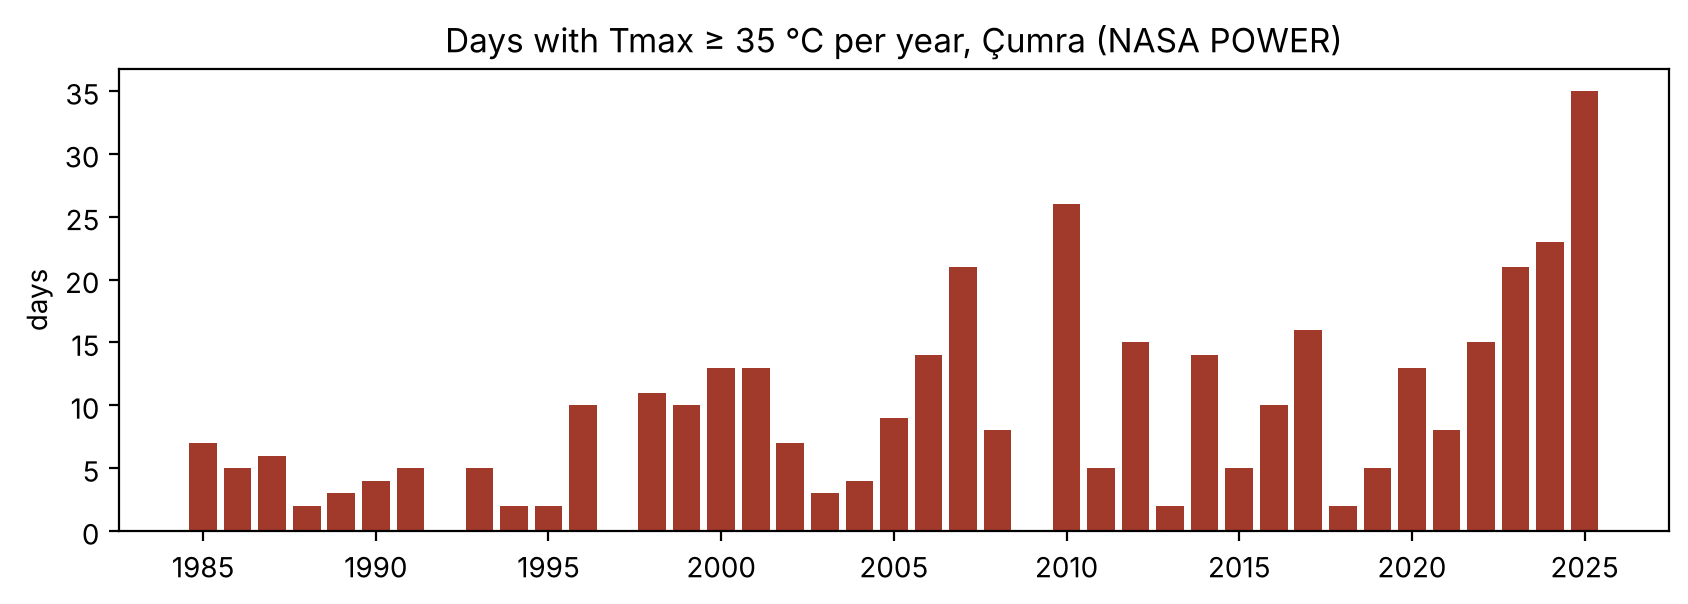

In [2]:
REGIONS = {"konya": 37.57, "kansas": None, "punjab": None, "california": None, "lamancha": None}
LON = {"konya": 32.77}

def get_weather(k, D):
    lat = REGIONS[k] or D["region"]["lat"]; lon = LON.get(k) or D["region"]["lon"]
    path = f"data/weather/{k}.csv.gz"
    try:
        w = fa.fetch_power(lat, lon); w.to_csv(path); src = "NASA POWER API (live)"
    except Exception as e:
        w = fa.load_weather(path); src = f"saved copy ({e.__class__.__name__})"
    return w, lat, src

D = fa.load_region("data/regions/konya.json")
w, lat, src = get_weather("konya", D)
print("Konya (Çumra):", w.shape[0], "days,", w.index.min().date(), "to", w.index.max().date(), "from", src)
hot = (w.tmax >= 35).groupby(w.index.year).sum()
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(hot.index, hot.values, color="#a13a2a"); ax.set_title("Days with Tmax ≥ 35 °C per year, Çumra (NASA POWER)"); ax.set_ylabel("days")
plt.show()

## 2. From average climate to real years
FieldRota v1 used one average number per crop. The agent needs good and bad years, so we turn FieldRota's calibrated averages into **year-by-year** values, keeping FieldRota's means and adding NASA POWER's year-to-year variation:

* water need = FieldRota need × (this season's ET₀ / 2011–2025 mean ET₀) (FAO-56 Hargreaves ET₀)
* rain = FieldRota rain × (this season's rain / 2011–2025 mean)
* well irrigation = need − effective rain (FieldRota's own effective-rain ratio)
* climate fit = FieldRota fit + *slope* × (hot days this year − mean), where hot days = days ≥ 35 °C in the crop's most heat-sensitive month and the *slope* (fit points lost per hot day) is fitted on FieldRota's 8 climate runs for that crop (past, now, 2041–2060 and 6 CMIP6 models).

**Check:** the 2011–2025 means below must match FieldRota's own numbers (columns `app_*`).

In [3]:
T = fa.build_year_table(D, w, lat, "now")
now = (T["years"] >= 2011) & (T["years"] <= 2025)
rows = []
for j, u in enumerate(T["crops"]):
    if T["meta"][u]["fallow"]: continue
    p = D["periods"]["now"][u]
    rows.append(dict(crop=D["crops"][u].get("en") or u, irrigation=T["irr"][now, j].mean(), app_irrigation=p["sulama"],
                     irrigation_sd=T["irr"][:, j].std(), fit=T["fit"][now, j].mean(), app_fit=p["uygunluk"],
                     fit_sd=T["fit"][:, j].std(), heat_slope=T["meta"][u]["heat_slope"]))
calib = pd.DataFrame(rows).round(1)
display(calib)
print("max |irrigation - app| =", (calib.irrigation - calib.app_irrigation).abs().max(), "mm")

,crop,irrigation,app_irrigation,irrigation_sd,fit,app_fit,fit_sd,heat_slope
0,Wheat,287.0,287,67.3,97.0,100,6.4,-2.2
1,Barley,228.0,228,68.1,100.0,100,0.0,-0.0
2,Chickpea,409.0,409,31.2,87.0,87,0.7,-0.2
3,Lentil,390.0,390,21.8,84.1,88,18.8,-5.0
4,Vetch,325.0,325,28.5,93.3,98,9.7,-4.7
5,Safflower,582.0,582,42.8,98.5,100,3.3,-2.7
6,Canola,219.0,219,69.9,100.0,100,0.0,0.0
7,Sunflower,552.0,552,26.9,84.1,88,18.8,-5.0
8,Dry bean,492.0,492,24.9,53.7,43,33.5,-4.3
9,Grain maize,547.0,547,33.3,84.1,87,21.3,-4.9


max |irrigation - app| = 0.0 mm


## 3. The field as a game: state, action, reward
* **State:** the last two crops on the field + one context signal (last year wet or dry when training on past weather; the decade when training on 2026–2060 futures).
* **Action:** next year's crop, limited to FieldRota's rules, checked year by year: on the crop list (Konya: Çumra 2027 list, so no sugar beet), three different crops in any three years, no fallow on irrigated land, in Konya no two high-water crops in a row, and the sowing date may not overlap the previous harvest.
* **Reward:** FieldRota's own score for one year, weighted by the farmer's goal (save water 7:2:1, healthy soil 2:2:6, balanced 4:3:3 for water : climate fit : soil). Soil health is the FieldRota soil score of the last 3 crops.
* **Learning:** tabular Q-learning, ε-greedy exploration, learning rate 1/visits^0.6, discount 0.9.

In [4]:
env = fa.FieldEnv(D, T, "water")
print(f"{env.n} crops, {int(env.allowed.sum())} allowed (crop, crop, next crop) moves out of {env.n**3}")
a2, a1 = env.crops.index("bugday"), env.crops.index("seker_pancari")
print("After wheat -> sugar beet, allowed next crops:", fa.names(D, [env.crops[a] for a in env.valid_actions(a2, a1)]))

15 crops, 1950 allowed (crop, crop, next crop) moves out of 3375
After wheat -> sugar beet, allowed next crops: Barley > Chickpea > Lentil > Vetch > Safflower > Sunflower > Dry bean > Onion


## 4. Test 1: unseen real weather (train 1986–2008, validate 2009–2014, test 2015–2025), Konya, goal "save water"

trained + tested in 40s; FieldRota v1 pick: Barley > Vetch > Canola


,policy,score,worst_year,irrigation_m3_da,climate_fit,soil,income_tl_da,rule_breaks
1,FieldRota-AI (RL),70.3,53.9,269.4,95.8,82.0,7740.6,0
3,Myopic (best this year),71.9,63.5,255.8,98.5,79.1,8951.6,0
5,FieldRota v1 suggestion,70.7,53.9,269.4,95.8,86.0,7740.6,0
7,Farmers: Grain maize > Wheat > Sugar beet,42.2,18.2,488.4,90.3,32.0,16399.6,7
9,Farmers: Wheat > Sunflower > Grain maize,42.3,15.0,466.0,79.3,32.0,10669.8,0
11,Farmers: Wheat > Sugar beet > Potato,40.2,17.4,502.5,73.3,60.0,21475.3,7
13,Farmers: Wheat > Fallow > Wheat,70.8,47.1,184.5,94.2,9.0,6265.2,11


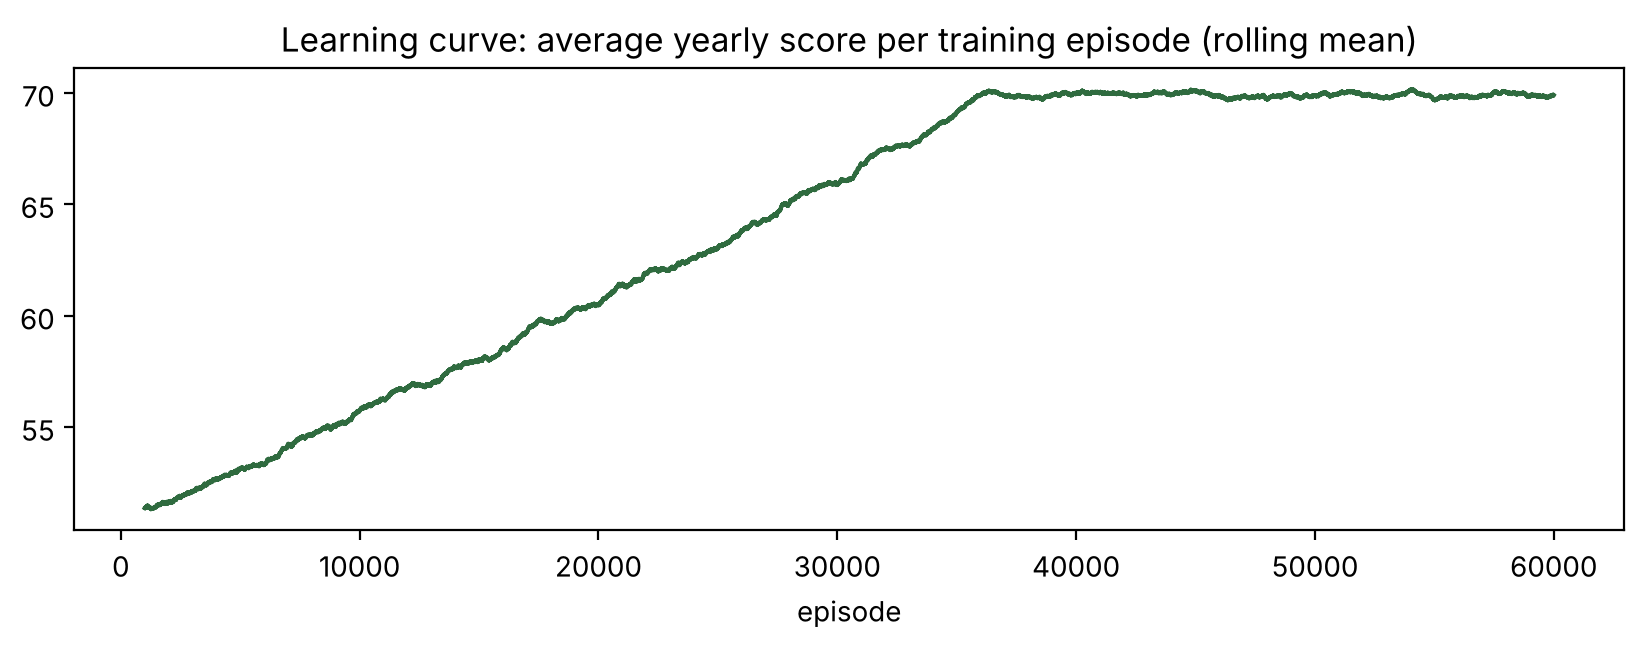

In [5]:
t0 = time.time()
h = fa.evaluate_region(D, w, lat, "water")
print(f"trained + tested in {time.time()-t0:.0f}s; FieldRota v1 pick: {fa.names(D, h['v1'])}")
R = h["results"].copy()
R["policy"] = [p if not p.startswith("Farmers: ") else "Farmers: " + fa.names(D, p[9:]) for p in R.policy]
R["plan"] = [fa.names(D, p) for p in R.plan]
cols = ["policy", "score", "worst_year", "irrigation_m3_da", "climate_fit", "soil", "income_tl_da", "rule_breaks"]
display(R[R.split == "test"][cols].round(1))
fig, ax = plt.subplots(figsize=(10, 3))
c = pd.Series(h["curve"]).rolling(1000).mean()
ax.plot(c, color="#2f6b3f"); ax.set_title("Learning curve: average yearly score per training episode (rolling mean)"); ax.set_xlabel("episode")
plt.show()

### One field, year by year: what goes in, what comes out, and where it fails
**Input:** a Çumra field whose last crops were wheat then sugar beet, goal *save water*. **Output:** the AI's crop for each test year (2015–2025, never seen in training), with well water, climate fit and the days ≥ 35 °C in that crop's most heat-sensitive month. The *baseline* is persistence: the farmer keeps today's rotation (maize → wheat → sugar beet).

In [6]:
pol = fa.rl_policy(h["env"], h["Q"]); te = fa.year_indices(h["T"], fa.TEST_YEARS)
ai_years = fa.rollout(h["env"], pol, te, ["bugday", "seker_pancari"])
base = fa.rollout(h["env"], fa.cycle_policy(h["env"], ["dane_misir", "bugday", "seker_pancari"]), te, ["bugday", "seker_pancari"])
col = {u: i for i, u in enumerate(h["T"]["crops"])}; yrs = list(h["T"]["years"])
tab = pd.DataFrame({"year": ai_years.year, "AI crop": [D["crops"][u]["en"] for u in ai_years.crop],
                    "AI score": ai_years.score, "AI well water": ai_years.irr, "AI climate fit": ai_years.fit,
                    "hot days (sensitive month)": [h["T"]["hot"][yrs.index(y), col[u]] for y, u in zip(ai_years.year, ai_years.crop)],
                    "baseline crop": [D["crops"][u]["en"] for u in base.crop], "baseline score": base.score, "baseline well water": base.irr})
display(tab.round(1))
worst = tab.loc[tab["AI score"].idxmin()]
print(f"Worst AI year: {int(worst.year)} ({worst['AI crop']}): {worst['hot days (sensitive month)']:.0f} hot days in its sensitive month, "
      f"climate fit {worst['AI climate fit']:.0f}. The AI picks the crop in autumn and cannot know the coming summer will be this hot.")

,year,AI crop,AI score,AI well water,AI climate fit,hot days (sensitive month),baseline crop,baseline score,baseline well water
0,2015,Barley,79.5,138.2,100.0,0.0,Grain maize,43.0,499.4
1,2016,Vetch,64.1,350.1,99.4,3.2,Wheat,55.4,372.6
2,2017,Canola,77.4,211.1,100.0,0.0,Sugar beet,25.4,653.0
3,2018,Barley,76.0,225.3,100.0,0.0,Grain maize,39.3,536.3
4,2019,Vetch,68.1,303.7,100.0,1.3,Wheat,72.7,204.0
5,2020,Canola,80.0,185.4,100.0,0.0,Sugar beet,22.3,695.1
6,2021,Barley,67.6,309.1,100.0,0.0,Grain maize,35.5,574.6
7,2022,Vetch,63.2,352.4,100.0,1.3,Wheat,67.9,251.6
8,2023,Canola,75.9,225.8,100.0,0.0,Sugar beet,18.2,638.6
9,2024,Barley,67.6,308.6,100.0,0.0,Grain maize,28.4,577.2


Worst AI year: 2025 (Vetch): 13 hot days in its sensitive month, climate fit 54. The AI picks the crop in autumn and cannot know the coming summer will be this hot.


## 5. Test 2: 2026–2060 under climate models the agent never saw
Each future year = the CMIP6 model's trend (linear from FieldRota's 2011–2025 values to the model's 2041–2060 values) + the de-trended anomaly of a real 1986–2025 year, so every future has realistic good and bad years. The agent trains on 3 models (ACCESS-CM2, EC-Earth3, MPI-ESM1-2-HR); we train it 3 times with different random seeds and keep the run that scores best on a 4th model (MRI-ESM2-0, validation). It is then tested on GFDL-ESM4 and IPSL-CM6A-LR, over 41 different weather sequences each. *Myopic* = picks the best crop for the current year only. *Best possible* = exact dynamic programming on the expected score.

In [7]:
t0 = time.time()
f = fa.evaluate_future(D, w, lat, "water")
print(f"trained + tested in {time.time()-t0:.0f}s")
F = f["results"].copy()
F["policy"] = [p if not p.startswith("Farmers: ") else "Farmers: " + fa.names(D, p[9:]) for p in F.policy]
display(F[F.split == "test models"][cols].round(1))
print("Best possible (exact DP, expected score) on the test models:", round(f["dp_opt"]["test models"], 1))
ai = F[(F.split == "test models") & F.policy.str.startswith("FieldRota-AI")].score.iloc[0]
print(f"The learned policy reaches {100*ai/f['dp_opt']['test models']:.1f}% of the optimum.")
path = f["paths"]["FieldRota-AI (RL)"]
print("AI pathway from the farmer's field (last crops: wheat, sugar beet):")
for (a, b) in fa.BUCKETS:
    print(f"  {a}-{b}:", fa.names(D, path[a-2026:b-2026+1][:6]), "...")

trained + tested in 68s


,policy,score,worst_year,irrigation_m3_da,climate_fit,soil,income_tl_da,rule_breaks
1,FieldRota-AI (RL),70.4,57.7,271.4,96.6,83.8,8473.4,0
3,Myopic (best this year),66.8,54.4,261.8,99.3,32.4,10684.0,0
5,"FieldRota v1, today's pick",70.3,57.3,274.3,96.2,86.0,8118.0,0
7,"FieldRota v1, 2050s pick",70.3,57.3,274.3,96.2,86.0,8118.0,0
9,Farmers: Grain maize > Wheat > Sugar beet,36.3,10.1,518.0,75.6,32.0,13373.6,1840


Best possible (exact DP, expected score) on the test models: 70.4
The learned policy reaches 100.0% of the optimum.
AI pathway from the farmer's field (last crops: wheat, sugar beet):
  2026-2035: Barley > Canola > Vetch > Barley > Canola > Vetch ...
  2036-2045: Canola > Vetch > Barley > Canola > Vetch > Barley ...
  2046-2060: Vetch > Barley > Canola > Vetch > Barley > Canola ...


## 6. All regions and goals

In [8]:
if RUN_ALL:
    subprocess.run([sys.executable, "export_ai.py"], check=True)
S = pd.concat([pd.read_csv(p) for p in sorted(__import__("glob").glob("results/summary_*.csv"))])
def short(p):
    return ("AI" if p.startswith("FieldRota-AI") else "v1" if p.startswith("FieldRota v1, today") or p == "FieldRota v1 suggestion"
            else "v1_2050s" if "2050s" in p else "farmers" if p.startswith("Farmers") else "myopic" if p.startswith("Myopic")
            else "optimum" if p.startswith("Best") else None)
S["who"] = S.policy.map(short)
first_farmer = S[S.who == "farmers"].groupby(["region", "goal", "eval"]).head(1)
S2 = pd.concat([S[S.who.isin(["AI", "v1", "myopic", "optimum"])], first_farmer])
tab = S2.pivot_table(index=["eval", "region", "goal"], columns="who", values="score").round(1)
display(tab)
water = S2[S2.goal == "water"].pivot_table(index=["eval", "region"], columns="who", values="irrigation_m3_da").round(0)
print("Well water, m3 per decare per year (goal = save water):"); display(water)

who                             AI  farmers  myopic  optimum    v1
eval        region     goal                                       
future_test california bal    88.9     37.8    88.9     88.9  88.9
                       soil   89.6     50.0    89.6     89.6  89.6
                       water  87.1     24.3    87.0     87.1  87.1
            kansas     bal    60.1     31.4    57.7     60.3  58.6
                       soil   76.7     43.7    77.2     77.2  76.2
                       water  44.5     13.0    44.5     44.7  44.1
            konya      bal    77.9     42.6    79.1     79.1  78.9
                       soil   83.5     39.5    83.3     84.3  84.0
                       water  70.4     36.3    66.8     70.4  70.3
            lamancha   bal    83.3     37.6    83.2     84.0  84.0
                       soil   87.6     29.4    88.0     88.0  88.4
                       water  78.3     31.6    78.3     78.3  78.2
            punjab     bal    65.9      5.2    66.1     66.1  65.2
                       soil   79.4     17.1    80.3     80.3  80.3
                       water  56.6    -10.3    56.8     56.8  56.8
hist_test   california bal    90.1     38.4    90.1      NaN  89.7
                       soil   90.3     50.3    90.3      NaN  89.9
                       water  89.7     24.9    88.8      NaN  89.0
            kansas     bal    64.1     41.7    61.3      NaN  64.2
                       soil   78.9     49.7    78.9      NaN  79.7
                       water  47.7     25.3    47.7      NaN  51.5
            konya      bal    80.9     48.7    81.0      NaN  79.1
                       soil   84.3     43.2    84.9      NaN  84.9
                       water  70.3     42.2    71.9      NaN  70.7
            lamancha   bal    82.9     38.8    83.3      NaN  84.4
                       soil   86.6     30.1    87.2      NaN  88.6
                       water  78.8     32.8    78.8      NaN  79.0
            punjab     bal    85.0     26.0    85.0      NaN  85.4
                       soil   90.8     29.0    90.8      NaN  92.2
                       water  78.8     16.4    78.8      NaN  79.1

Well water, m3 per decare per year (goal = save water):


who                        AI  farmers  myopic     v1
eval        region                                   
future_test california  151.0    880.0   151.0  151.0
            kansas      387.0    579.0   386.0  384.0
            konya       271.0    518.0   262.0  274.0
            lamancha    213.0    613.0   213.0  215.0
            punjab      409.0   1066.0   407.0  408.0
hist_test   california  110.0    874.0   119.0  119.0
            kansas      375.0    510.0   375.0  345.0
            konya       269.0    488.0   256.0  269.0
            lamancha    207.0    605.0   207.0  205.0
            punjab      206.0    813.0   206.0  208.0

In [9]:
fut = tab.loc["future_test"]
gap_v1 = (fut["AI"] - fut["v1"])
gap_opt = 100 * fut["AI"] / fut["optimum"]
print(f"Unseen climate models: AI vs v1 = {gap_v1.mean():+.2f} points on average (min {gap_v1.min():+.1f}, max {gap_v1.max():+.1f})")
print(f"AI reaches {gap_opt.mean():.1f}% of the exact optimum on average (worst case {gap_opt.min():.1f}%)")
print(f"AI vs farmers' common rotation: {(fut['AI'] - fut['farmers']).mean():+.1f} points")
w_ = water.loc["future_test"]
print(f"Well water, save-water goal: AI {w_['AI'].mean():.0f} vs farmers {w_['farmers'].mean():.0f} m3/da/yr "
      f"({100*(1 - w_['AI'].mean()/w_['farmers'].mean()):.0f}% less)")

Unseen climate models: AI vs v1 = -0.05 points on average (min -1.0, max +1.5)
AI reaches 99.5% of the exact optimum on average (worst case 98.5%)
AI vs farmers' common rotation: +46.7 points
Well water, save-water goal: AI 286 vs farmers 731 m3/da/yr (61% less)


## 7. Robustness: does the answer depend on luck or on our assumptions?
We retrain the Konya "save water" agent with different random seeds and with the heat sensitivity halved or doubled, and check whether the score and the first-decade plan change.

In [10]:
def konya_run(seed=0, heat_mult=1.0):
    T2 = fa.build_year_table(D, w, lat, "now")
    for u in T2["meta"]:
        if not T2["meta"][u]["fallow"]: T2["meta"][u]["heat_slope"] *= heat_mult
    env2 = fa.FieldEnv(D, T2, "water")
    tables = {m: fa.future_tables(D, T2, m) for m in D["models"]}
    Q, _ = fa.train_q_future(env2, tables, fa.TRAIN_MODELS, episodes=100000, seed=seed)
    pol = lambda a2, a1, b, t: (lambda acts: acts[np.argmax(Q[a2, a1, b, acts])] if len(acts) else None)(env2.valid_actions(a2, a1))
    sc = np.mean([fa.future_rollout(env2, pol, tables, m, h0, ["bugday", "seker_pancari"]).score.mean() for m in fa.TEST_MODELS for h0 in range(len(T2["years"]))])
    plan = list(fa.future_rollout(env2, pol, tables, fa.TEST_MODELS[0], 0, ["bugday", "seker_pancari"]).crop[:9])
    return sc, fa.names(D, plan)
rob = [dict(run=f"seed {s}", **dict(zip(["score", "plan 2026-2034"], konya_run(seed=s)))) for s in range(3)]
rob += [dict(run=f"heat sensitivity x{m}", **dict(zip(["score", "plan 2026-2034"], konya_run(heat_mult=m)))) for m in (0.5, 2.0)]
display(pd.DataFrame(rob).round(2))
print("Note: changing the heat sensitivity changes the reward itself, so compare plans, not scores, across those rows.")

,run,score,plan 2026-2034
0,seed 0,70.17,Vetch > Wheat > Canola > Vetch > Barley > Canola > Vetch...
1,seed 1,70.44,Barley > Canola > Vetch > Barley > Canola > Vetch > Barl...
2,seed 2,70.37,Vetch > Canola > Barley > Vetch > Canola > Barley > Vetc...
3,heat sensitivity x0.5,69.16,Barley > Vetch > Canola > Barley > Vetch > Canola > Barl...
4,heat sensitivity x2.0,70.20,Barley > Canola > Vetch > Barley > Canola > Vetch > Barl...


Note: changing the heat sensitivity changes the reward itself, so compare plans, not scores, across those rows.


## 8. Where it fails, and what we did not model
* **The AI is usually not better than FieldRota v1.** In most region/goal pairs the learned policy and v1's exhaustive search reach almost the same plan; the optimum itself is close to a fixed rotation, because the climate trend is slow compared with a 3-year cycle. The AI's value is that it (1) starts from the farmer's real field history, (2) plans through 2060 and switches crops when the decades warm (e.g. Kansas), and (3) independently confirms v1. Where it is a little below v1 (e.g. Konya, soil goal), it is because it learns from noisy single years.
* **Myopic planning fails on soil:** picking the best crop each year without looking ahead lowers soil health sharply in Konya; looking ahead is what the agent learns.
* **Not modelled:** crop yields (climate fit stands in for them), prices in the score (Konya income is shown, but not optimised), pests and diseases beyond the soil score, soil moisture carried over between seasons, double cropping beyond Punjab's crop pairs, and the farmer's costs. Climate data covers about 50 km; NASA POWER rain outside Konya was not checked against stations.
* **Future climate:** a delta method (trend + real-year anomalies), not daily CMIP6 weather; only one emissions scenario (SSP2-4.5).

## 9. Export for the FieldRota web app
`export_ai.py` writes `ai/<region>.json`: the learned policy (best next crop for every pair of previous crops and every decade) and the test results. The web app (`app/index.html`, section 5) reads it and shows the AI's plan starting from the crops the farmer enters.

In [11]:
A = json.load(open("ai/konya.json", encoding="utf-8"))
print("policy entries per goal:", {g: len(v["policy"]) for g, v in A["goals"].items()})
print("example: after wheat -> sugar beet, the 'save water' policy plants:", fa.names(D, A["goals"]["water"]["policy"]["bugday|seker_pancari"]), "in", A["buckets"])

policy entries per goal: {'water': 196, 'soil': 196, 'bal': 196}
example: after wheat -> sugar beet, the 'save water' policy plants: Barley > Barley > Vetch in [[2026, 2035], [2036, 2045], [2046, 2060]]


## Credits
* **Data:** NASA POWER daily agroclimatology (power.larc.nasa.gov); NASA NEX-GDDP-CMIP6, SSP2-4.5 (6 models), as processed in FieldRota; FAO-56 (Allen et al. 1998) for ET₀ and crop coefficients; Çumra crop water use, TAGEM–DSİ (2017); Çumra 2027 planting rules and support payments, Türkiye Ministry of Agriculture and Forestry; prices as listed in the app.
* **Libraries:** NumPy, pandas, Matplotlib; D3 and topojson-client in the web app.
* **AI tools:** Claude (Anthropic) was used to help write and debug code and text; every part was reviewed by the team.